## Generate cell population data for figure 3 for all six conditions

In [1]:
import os
import sys
sys.path.insert(0, "./cellular_cycle") # add path to the model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime

## Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count

# to match Austin's ouput and use his functions, simulation with ODE should use omega=1 and stochastic with omega=200 (the default)
from cell_cycle_death_model import model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [2]:
from Cell_Population_Simulation import Cell_Population_Simulation

In [3]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt(os.getcwd() + '/model_data/sampled_parameter_names.txt', dtype=str)

In [4]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/model_data/parameters.csv')
del new_param['Stress']
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
F_n.1
K_p21fak.1
k_CDF
K_DF
K_dcescp2


In [5]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv(os.getcwd() + '/model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

BAXm_0
BCL2_0


In [6]:
model.parameters["a_stress"].value

0.6515

In [17]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv(os.getcwd() + '/model_data/ECM_conditions_2.csv')
condition = "0.6 kPa DMSO"

In [18]:
# Set the species AKT, ERK, FAK with species and value col
# for input in ["AKT", "ERK", "FAK"]:
#     model.parameters[input].value = ECM_conditions[
#         (ECM_conditions["condition"] == condition) & (ECM_conditions["species"] == input)].value

# Set inputs for Cell_Population_Simulation function
init = 5
run_time = 120
observed_cells_time = 120

# Run the model
# Simulate Check_Model_Consistency
# (variable_range, check, tmp_score) = Check_Model_Consistency(model, thr=0.26, return_plot=True)

(cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names)

0.6 kPa DMSO
BAXm_0
BCL2_0


2023-09-26 10:11:21.030 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


In [9]:
def plot_cell_count(cell_count, run_time):
    t_sim = np.arange(0, run_time, 1 / 3)
    cell_count_t = np.zeros(len(t_sim))
    time_tmp_m = 0
    for time_tmp_p, cell_count_time_tmp in cell_count:
        cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
        time_tmp_m = time_tmp_p
    DIP_sim = np.log2(cell_count_t / cell_count_t[0])
    fig, ax = plt.subplots()
    ax.scatter(t_sim, DIP_sim, color="black", s=1)
    ax.set_xlabel('Time (h)')
    ax.set_ylabel('DIP')
    plt.show()

    return fig, ax

In [ ]:
cells['molecules'][3]

In [ ]:
model.parameters['AKT'].value

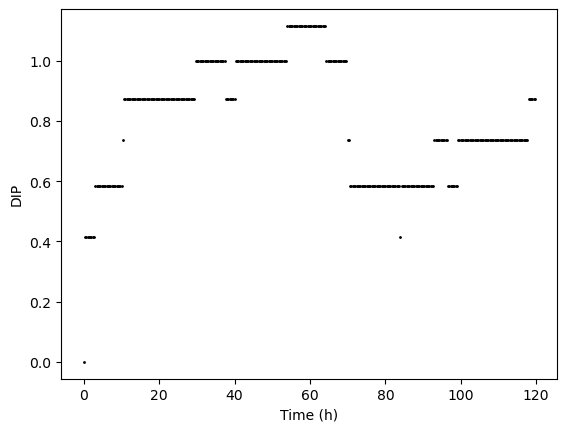

(<Figure size 640x480 with 1 Axes>, <Axes: xlabel='Time (h)', ylabel='DIP'>)

In [16]:
plot_cell_count(cell_count, run_time)

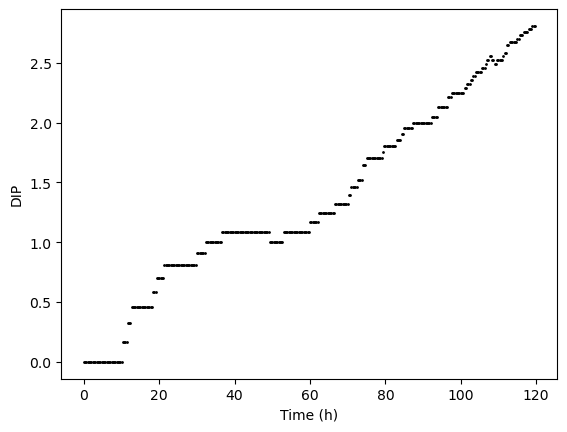

(<Figure size 640x480 with 1 Axes>, <Axes: xlabel='Time (h)', ylabel='DIP'>)

In [19]:
plot_cell_count(cell_count, run_time)

In [29]:
from call_cell_events import call_events #
from retrieve_cellState_dw_2 import retrieve_cellState #

  Starting cell End_of_Expt  Death   Birthtime   Lifespan
0         False       False  False           0  24.280936
1         False       False  False   24.280936  24.280936
2         False       False  False   48.561873  16.354515
3         False       False  False   64.916388  34.715719
4         False       False  False   99.632107  16.153846
5         False        True  False  115.785953   4.113712
6         False       False  False           0  34.916388
7         False       False  False   34.916388  47.859532
8         False        True  False    82.77592  37.123746
{'Starting cell': True, 'End_of_Expt': False, 'Death': False, 'Birthtime': 0, 'Lifespan': 7.224080267559}
   Starting cell End_of_Expt  Death   Birthtime   Lifespan
0          False       False  False           0  24.280936
1          False       False  False   24.280936  24.280936
2          False       False  False   48.561873  16.354515
3          False       False  False   64.916388  34.715719
4          False   

(0.0, 125.0)

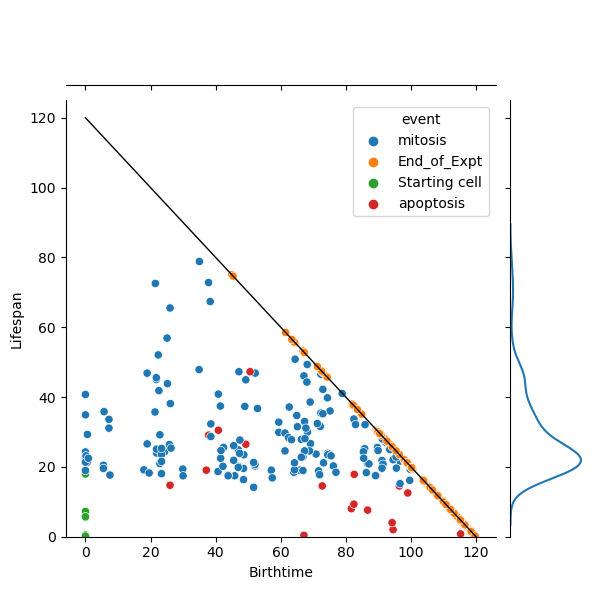

In [30]:
IMT_eoe_counts, all_prot = retrieve_cellState(run_time, cells, return_all_prot=True);
all_events_simulated = call_events(run_time, IMT_eoe_counts); #Gives all events (apoptosis, mitosis, quiescence) and when they happen

#plot the results
grid = sns.JointGrid(x='Birthtime', y='Lifespan', data=all_events_simulated) #x axis = birthtime of a cell, y = endtime of this cell
g = grid.plot_joint(sns.scatterplot, hue='event', data=all_events_simulated) 
g.ax_joint.plot([run_time, 0], [0, run_time], 'b-', linewidth = 1, color='black') #Recorded events behind this line
sns.kdeplot(all_events_simulated.loc[all_events_simulated['event']=='mitosis', 'Lifespan'].to_list(), 
            ax=g.ax_marg_y, vertical=True, legend=False, bw=0.3) #output distribution of intermitotic times
plt.ylim(0, 125)

In [23]:
conditions = ['55 kPa DMSO']
#conditions = ['4 kPa erlotinib', '4 kPa DMSO', '55 kPa erlotinib', '55 kPa DMSO']
import pickle

for condition in conditions:
    for num in range(3):
        init = 5
        
        (cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names)
        
        filename = Path(SAVE_DIR, f'cells_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            with open(filename, 'wb') as f:
                pickle.dump(cells, f, protocol=pickle.HIGHEST_PROTOCOL)
        else:
            print(f"File {filename} already exists. Skipping...")
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            np.savetxt(filename, cell_count, delimiter=',')
        else:
            print(f"File {filename} already exists. Skipping...")

55 kPa DMSO
BAXm_0
BCL2_0


2023-09-26 11:44:38.234 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


Saving to C:\Users\olesk\ECM_mod_output\cells_55 kPa DMSO_0_param_orig.csv...
Saving to C:\Users\olesk\ECM_mod_output\cellcount_55 kPa DMSO_0_param_orig.csv...
55 kPa DMSO
BAXm_0
BCL2_0


2023-09-26 11:49:20.823 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


Saving to C:\Users\olesk\ECM_mod_output\cells_55 kPa DMSO_1_param_orig.csv...
Saving to C:\Users\olesk\ECM_mod_output\cellcount_55 kPa DMSO_1_param_orig.csv...
55 kPa DMSO
BAXm_0
BCL2_0


2023-09-26 11:56:01.450 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


Saving to C:\Users\olesk\ECM_mod_output\cells_55 kPa DMSO_2_param_orig.csv...
Saving to C:\Users\olesk\ECM_mod_output\cellcount_55 kPa DMSO_2_param_orig.csv...


In [24]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO']
import pickle

for condition in conditions:
    for num in range(3):
        init = 10
        
        (cells, cell_count) = Cell_Population_Simulation(init, run_time, observed_cells_time, model, ECM_conditions, condition, sampled_parameter_names)
        
        filename = Path(SAVE_DIR, f'cells_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            with open(filename, 'wb') as f:
                pickle.dump(cells, f, protocol=pickle.HIGHEST_PROTOCOL)
        else:
            print(f"File {filename} already exists. Skipping...")
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')
        if OVERWRITE or not os.path.exists(filename):
            print(f"Saving to {filename}...")
            np.savetxt(filename, cell_count, delimiter=',')
        else:
            print(f"File {filename} already exists. Skipping...")

0.6 kPa erlotinib
BAXm_0
BCL2_0


2023-09-26 12:04:16.277 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


Saving to C:\Users\olesk\ECM_mod_output\cells_0.6 kPa erlotinib_0_param_orig.csv...
Saving to C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa erlotinib_0_param_orig.csv...
0.6 kPa erlotinib
BAXm_0
BCL2_0


2023-09-26 12:05:10.803 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


Saving to C:\Users\olesk\ECM_mod_output\cells_0.6 kPa erlotinib_1_param_orig.csv...
Saving to C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa erlotinib_1_param_orig.csv...
0.6 kPa erlotinib
BAXm_0
BCL2_0


...

Saving to C:\Users\olesk\ECM_mod_output\cells_0.6 kPa DMSO_0_param_orig.csv...
Saving to C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa DMSO_0_param_orig.csv...
0.6 kPa DMSO
BAXm_0
BCL2_0


2023-09-26 12:11:10.418 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


Saving to C:\Users\olesk\ECM_mod_output\cells_0.6 kPa DMSO_1_param_orig.csv...
Saving to C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa DMSO_1_param_orig.csv...
0.6 kPa DMSO
BAXm_0
BCL2_0


2023-09-26 12:14:42.862 - pysb.simulator.scipyode - WARNING - [cell_cycle_death_model] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing the 'cython' package for compiling the ODEs to C code. This warning can be suppressed by specifying compiler='python'.


Saving to C:\Users\olesk\ECM_mod_output\cells_0.6 kPa DMSO_2_param_orig.csv...
Saving to C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa DMSO_2_param_orig.csv...


Loading C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa erlotinib_0_param_orig.csv...
Loading C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa erlotinib_1_param_orig.csv...
Loading C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa erlotinib_2_param_orig.csv...
Loading C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa DMSO_0_param_orig.csv...
Loading C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa DMSO_1_param_orig.csv...
Loading C:\Users\olesk\ECM_mod_output\cellcount_0.6 kPa DMSO_2_param_orig.csv...


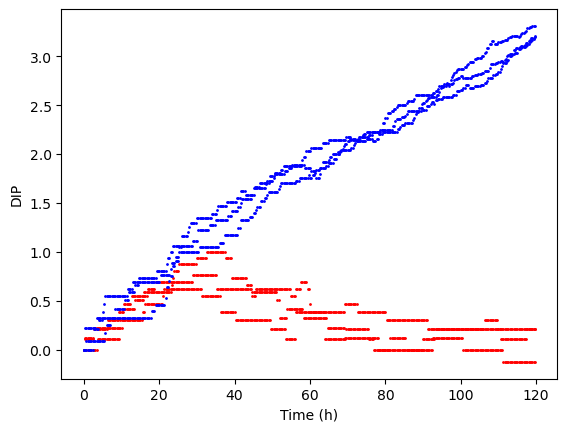

In [26]:
conditions = ['0.6 kPa erlotinib', '0.6 kPa DMSO']

fig, ax = plt.subplots()
for condition in conditions:
    for num in range(3):
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')

        print(f"Loading {filename}...")
        cell_count = np.loadtxt(filename, delimiter=',')
        
        t_sim = np.arange(0, 120, 1 / 3)
        cell_count_t = np.zeros(len(t_sim))
        time_tmp_m = 0
        for time_tmp_p, cell_count_time_tmp in cell_count:
            cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
            time_tmp_m = time_tmp_p
        DIP_sim = np.log2(cell_count_t / cell_count_t[0])
        if "erlotinib" in str(filename):
            ax.scatter(t_sim, DIP_sim, color="red", s=1)
        else:
            ax.scatter(t_sim, DIP_sim, color="blue", s=1)
ax.set_xlabel('Time (h)')
ax.set_ylabel('DIP')
plt.show()

Loading C:\Users\olesk\ECM_mod_output\cellcount_4 kPa erlotinib_0_param_orig.csv...
Loading C:\Users\olesk\ECM_mod_output\cellcount_4 kPa erlotinib_1_param_orig.csv...
Loading C:\Users\olesk\ECM_mod_output\cellcount_4 kPa erlotinib_2_param_orig.csv...
Loading C:\Users\olesk\ECM_mod_output\cellcount_4 kPa DMSO_0_param_orig.csv...
Loading C:\Users\olesk\ECM_mod_output\cellcount_4 kPa DMSO_1_param_orig.csv...
Loading C:\Users\olesk\ECM_mod_output\cellcount_4 kPa DMSO_2_param_orig.csv...


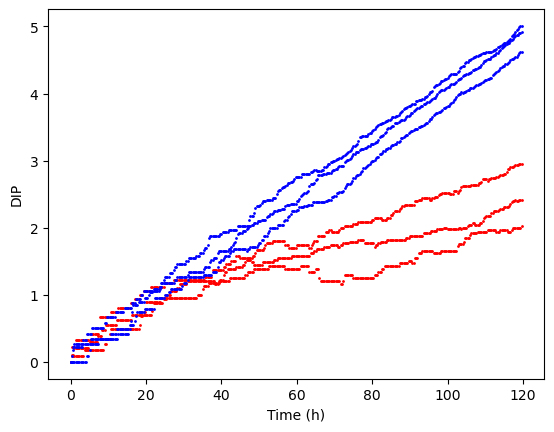

In [25]:
conditions = ['4 kPa erlotinib', '4 kPa DMSO']

fig, ax = plt.subplots()
for condition in conditions:
    for num in range(3):
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')

        print(f"Loading {filename}...")
        cell_count = np.loadtxt(filename, delimiter=',')
        
        t_sim = np.arange(0, 120, 1 / 3)
        cell_count_t = np.zeros(len(t_sim))
        time_tmp_m = 0
        for time_tmp_p, cell_count_time_tmp in cell_count:
            cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
            time_tmp_m = time_tmp_p
        DIP_sim = np.log2(cell_count_t / cell_count_t[0])
        if "erlotinib" in str(filename):
            ax.scatter(t_sim, DIP_sim, color="red", s=1)
        else:
            ax.scatter(t_sim, DIP_sim, color="blue", s=1)
ax.set_xlabel('Time (h)')
ax.set_ylabel('DIP')
plt.show()

Loading C:\Users\olesk\ECM_mod_output\cellcount_55 kPa erlotinib_0_param_orig.csv...
Loading C:\Users\olesk\ECM_mod_output\cellcount_55 kPa erlotinib_1_param_orig.csv...
Loading C:\Users\olesk\ECM_mod_output\cellcount_55 kPa erlotinib_2_param_orig.csv...
Loading C:\Users\olesk\ECM_mod_output\cellcount_55 kPa DMSO_0_param_orig.csv...
Loading C:\Users\olesk\ECM_mod_output\cellcount_55 kPa DMSO_1_param_orig.csv...
Loading C:\Users\olesk\ECM_mod_output\cellcount_55 kPa DMSO_2_param_orig.csv...


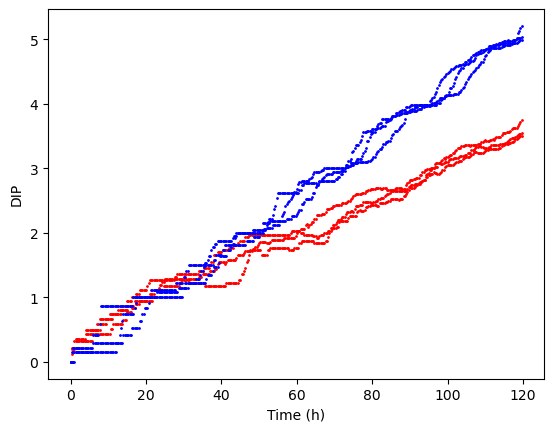

In [27]:
conditions = ['55 kPa erlotinib', '55 kPa DMSO']

fig, ax = plt.subplots()
for condition in conditions:
    for num in range(3):
            
        filename = Path(SAVE_DIR, f'cellcount_{condition}_{num}_param_orig.csv')

        print(f"Loading {filename}...")
        cell_count = np.loadtxt(filename, delimiter=',')
        
        t_sim = np.arange(0, 120, 1 / 3)
        cell_count_t = np.zeros(len(t_sim))
        time_tmp_m = 0
        for time_tmp_p, cell_count_time_tmp in cell_count:
            cell_count_t[(time_tmp_m <= t_sim) & (t_sim < time_tmp_p)] = cell_count_time_tmp
            time_tmp_m = time_tmp_p
        DIP_sim = np.log2(cell_count_t / cell_count_t[0])
        if "erlotinib" in str(filename):
            ax.scatter(t_sim, DIP_sim, color="red", s=1)
        else:
            ax.scatter(t_sim, DIP_sim, color="blue", s=1)
ax.set_xlabel('Time (h)')
ax.set_ylabel('DIP')
plt.show()